# Fed funds rate changes — ARMA–GARCH with makystats

**Series.** Daily change in the U.S. **effective federal funds rate** (FRED `DFF`), sample **2005-01-01 → 2019-12-31**.

**Why this series for AR + MA?** Policy rates are highly persistent in levels; **first differences** still carry short-run serial correlation (implementation lags, calendar effects) while exhibiting **volatility clustering** around stress episodes (2008–09). Unlike daily equity excess returns, an **ARMA mean is not optional decoration**.

**Goal.** Step from a weak model to ARMA–GARCH, justifying each lag with tests and BIC — joint MLE throughout.

**Links.** [PyPI](https://pypi.org/project/makystats/) · [Docs](https://lauret-boris.github.io/makystats/) · [GitHub](https://github.com/Lauret-Boris/makystats)


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from makystats import arma_garch, select_order
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.0)

## 2. Data


In [2]:
path = "data/fed_funds_daily.csv"
df = pd.read_csv(path, parse_dates=True, index_col=0)
y = df["dDFF"].dropna().astype(float)
y.name = "dDFF"
print(path)
print(y.index.min().date(), "→", y.index.max().date(), len(y))
y.describe().round(4)


data/fed_funds_daily.csv
2005-01-02 → 2019-12-31 5477


count    5477.0000
mean       -0.0001
std         0.0593
min        -0.9500
25%         0.0000
50%         0.0000
75%         0.0000
max         1.0500
Name: dDFF, dtype: float64

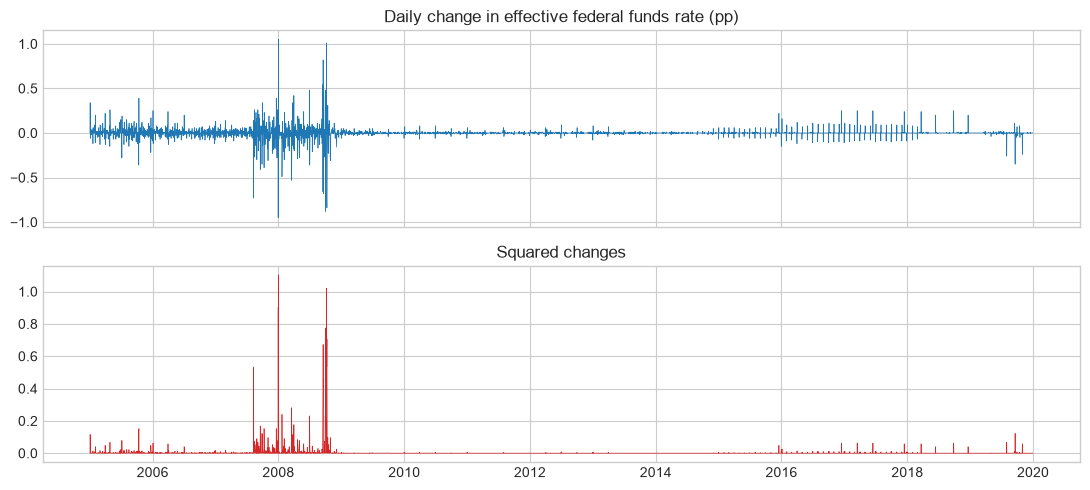

Ljung–Box levels


,lb_stat,lb_pvalue
5,324.8022,0.0
10,636.3523,0.0
20,750.9616,0.0


Ljung–Box squares


,lb_stat,lb_pvalue
5,2804.9566,0.0
10,3489.1664,0.0
20,4622.5989,0.0


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(y, lw=0.5)
axes[0].set_title("Daily change in effective federal funds rate (pp)")
axes[1].plot(y**2, lw=0.5, color="C3")
axes[1].set_title("Squared changes")
fig.tight_layout()
plt.show()

def lb(s, title):
    d = acorr_ljungbox(s, lags=[5, 10, 20], return_df=True)
    print(title); display(d.round(4))
lb(y - y.mean(), "Ljung–Box levels")
lb((y - y.mean())**2, "Ljung–Box squares")

**Reading.** Levels **and** squares reject white noise. Agenda: variance model **and** short mean dynamics.

## 3. Step A — Constant mean, constant variance


In [4]:
def report(name, res):
    print("=== %s ===" % name)
    print("LogL=%.2f  AIC=%.2f  BIC=%.2f" % (res.loglik, res.aic, res.bic))
    print("LB resid p=%.4g | LB resid2 p=%.4g" % (res.ljungbox_resid_pval, res.ljungbox_resid2_pval))
    display(res.coef_table.round(4))

res_A = arma_garch(y, mean="Constant", ar=0, ma=0, r=0, s=0, dist="normal", trend="c").fit(verbose=False)
res_A.summary()


   ARMA(0,0) - GARCH(0,0) — MLE (MLE)
   Mean: Constant  |  trend=c  |  Distribution: NORMAL  |  Optimiseur: BFGS non contraint (reparam.)
   Backcast exponentiel: lambda = 0.7  |  Cov: OPG
Log-Likelihood : 7705.418912
AIC            : -15406.8378
BIC            : -15393.6212
Observations   : 5477
Paramètres     : 2

--- Coefficients (IC 95% dans self.coef_table) ---
          Coeff   Std.Err      z-Stat     Prob.  CI_low_95  CI_high_95
const -0.000077  0.000802   -0.095681  0.923774  -0.001648    0.001494
omega  0.003512  0.000009  384.905763  0.000000   0.003494    0.003530

--- Diagnostic ---
alpha+beta = 0.000000
Ljung-Box (10) sur résidus std : p-val = 0.0000
Ljung-Box (10) sur carrés std  : p-val = 0.0000
Jarque-Bera (normalité résidus std) : stat=2584331.4059  p-val=0.0000


## 4. Step B — Constant mean + GARCH(1,1)


In [5]:
res_B = arma_garch(
    y, mean="Constant", ar=0, ma=0, vol="GARCH", r=1, s=1, dist="normal", trend="c"
).fit(verbose=False)
report("B — Constant + GARCH(1,1)", res_B)

=== B — Constant + GARCH(1,1) ===
LogL=11956.61  AIC=-23905.23  BIC=-23878.80
LB resid p=1.06e-18 | LB resid2 p=0.9368


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,-0.0001,0.0003,-0.4440,0.657,-0.0007,0.0004
omega,0.0000,0.0000,93.6914,0.000,0.0000,0.0000
alpha(1),0.0941,0.0011,87.9843,0.000,0.0920,0.0962
beta(1),0.9129,0.0007,1218.5133,0.000,0.9114,0.9144


**Diagnosis B.** Huge IC gain (clustering). Residual **level** Ljung–Box still fails → need mean lags, not a larger GARCH order first.


## 5. Step C — Short mean dynamics under GARCH(1,1)

Compare constant, AR(1), MA(1), ARMA(1,1) **with the same GARCH(1,1)**. Prefer **BIC**. Do not open a large ARMA grid before these four.


In [6]:
cands = {}
for name, kw in [
    ("Const+G", dict(mean="Constant", ar=0, ma=0)),
    ("AR(1)+G", dict(mean="AR", ar=1, ma=0)),
    ("MA(1)+G", dict(mean="ARMA", ar=0, ma=1)),
    ("ARMA(1,1)+G", dict(mean="ARMA", ar=1, ma=1)),
]:
    cands[name] = arma_garch(
        y, vol="GARCH", r=1, s=1, dist="normal", trend="c", **kw
    ).fit(verbose=False)

comp = pd.DataFrame([
    {
        "model": k,
        "AIC": v.aic,
        "BIC": v.bic,
        "LB_resid_p": v.ljungbox_resid_pval,
        "LB_resid2_p": v.ljungbox_resid2_pval,
    }
    for k, v in cands.items()
]).set_index("model")
display(comp.round(4))
res_C = cands["ARMA(1,1)+G"]
report("C — ARMA(1,1)–GARCH(1,1)", res_C)

,AIC,BIC,LB_resid_p,LB_resid2_p
model,,,,
Const+G,-23905.2294,-23878.7961,0.000,0.9368
AR(1)+G,-23940.3189,-23907.2782,0.000,0.9554
MA(1)+G,-23955.5899,-23922.5492,0.000,0.9577
"ARMA(1,1)+G",-24035.0933,-23995.4445,0.044,0.9646


=== C — ARMA(1,1)–GARCH(1,1) ===
LogL=12023.55  AIC=-24035.09  BIC=-23995.44
LB resid p=0.04398 | LB resid2 p=0.9646


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,-0.0001,0.0002,-0.6079,0.5432,-0.0004,0.0002
AR(1),0.5922,0.0373,15.8944,0.0000,0.5191,0.6652
MA(1),-0.7686,0.0321,-23.9170,0.0000,-0.8316,-0.7056
omega,0.0000,0.0000,76.6241,0.0000,0.0000,0.0000
alpha(1),0.0855,0.0011,79.8812,0.0000,0.0834,0.0876
beta(1),0.9193,0.0009,1070.7760,0.0000,0.9176,0.9210


**Diagnosis C.** On this sample, **ARMA(1,1)–GARCH(1,1)** typically dominates BIC and is the first specification where residual level Ljung–Box becomes only borderline. AR and MA coefficients are both significant — unlike the near-cancellation pattern on many equity return series.

**Note.** Student-\(t\) GARCH on this rate-change series can become numerically fragile (near unit AR/MA cancellation, extreme \(\nu\)). We stay with **Gaussian** innovations unless diagnostics clearly demand otherwise.


## 6. Theory-guided `select_order` (makystats)

The four hand fits above motivate the grid. Now let **`select_order`** rank models under a common sample.

| Dimension | Grid | Reason |
|-----------|------|--------|
| p, q | 0…2 | Short rate dynamics; AR and MA both allowed |
| r, s | 1 | GARCH(1,1) |
| dist | normal | Stable on this series (Student-t can be fragile) |
| `mean` | **`"AR"`** | Enables p/q search (do not use `mean="ARMA"` inside `select_order`) |
| criterion | BIC | |

`return_best=True` yields the fitted object for section 7.


In [7]:
table, best = select_order(
    y,
    p_range=range(0, 3),
    q_range=range(0, 3),
    r_range=[1],
    s_range=[1],
    dist=["normal"],
    variance_model=["garch"],
    criterion="bic",
    mean="AR",
    trend="c",
    verbose=False,
    n_jobs=1,
    return_best=True,
)
display(table[["aic", "bic", "ok"]].sort_values("bic").head(8))
print("Best by BIC:", table.attrs.get("best"))
print(best.coef_table.round(4))

,aic,bic,ok
label,,,
"ARMA(2,1)-garch(1,1)-normal",-24047.552309,-24001.296676,True
"ARMA(1,1)-garch(1,1)-normal",-24036.083014,-23996.435329,True
"ARMA(0,2)-garch(1,1)-normal",-23995.592671,-23955.944985,True
"ARMA(2,0)-garch(1,1)-normal",-23985.968585,-23946.320899,True
"ARMA(2,2)-garch(1,1)-normal",-23991.136717,-23938.273137,True
"ARMA(0,1)-garch(1,1)-normal",-23958.785796,-23925.746058,True
"ARMA(1,0)-garch(1,1)-normal",-23942.107096,-23909.067359,True
"ARMA(0,0)-garch(1,1)-normal",-23906.496016,-23880.064226,True


Best by BIC: ARMA(2,1)-garch(1,1)-normal
           Coeff  Std.Err     z-Stat   Prob.  CI_low_95  CI_high_95
const    -0.0001   0.0002    -0.5666  0.5710    -0.0004      0.0002
AR(1)     0.5878   0.0506    11.6270  0.0000     0.4887      0.6869
AR(2)    -0.0254   0.0229    -1.1110  0.2666    -0.0702      0.0194
MA(1)    -0.7522   0.0493   -15.2571  0.0000    -0.8489     -0.6556
omega     0.0000   0.0000    74.3574  0.0000     0.0000      0.0000
alpha(1)  0.0833   0.0011    77.7905  0.0000     0.0812      0.0854
beta(1)   0.9215   0.0009  1077.2198  0.0000     0.9199      0.9232


## 7. Preferred fit — diagnostics & volatility

Plots use the **`select_order`** winner (joint MLE, orders chosen by BIC on a theory-shaped grid).


Selected: ARMA(2,1)-garch(1,1)-normal BIC=-24001.30


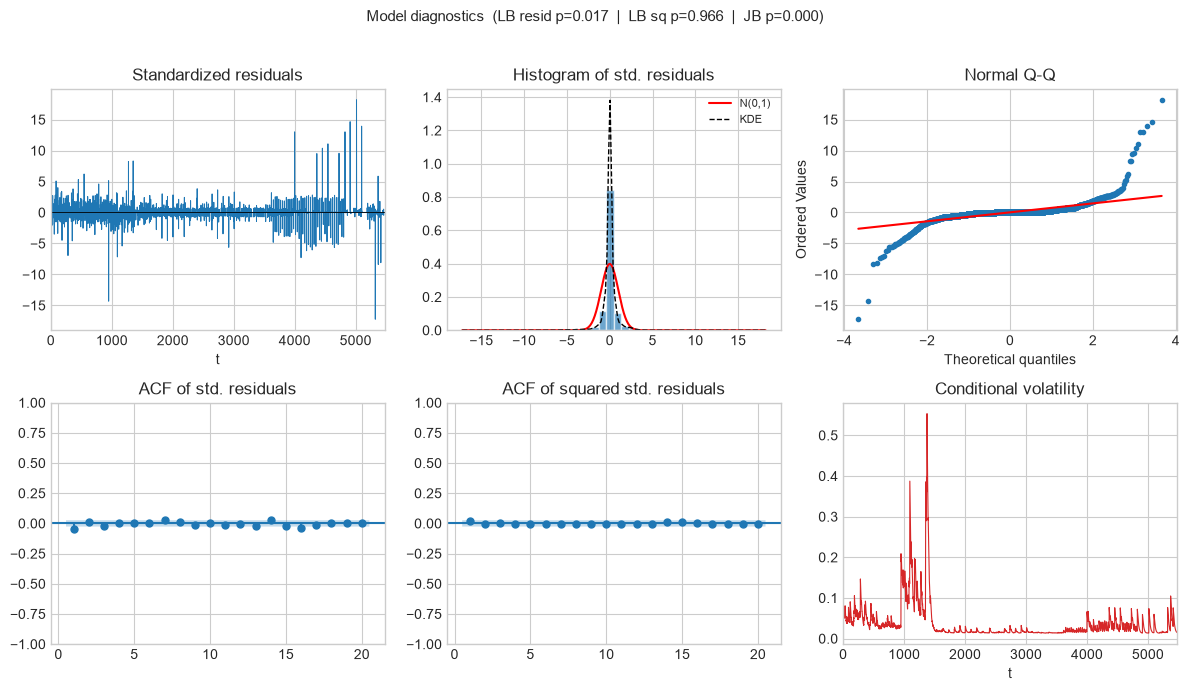

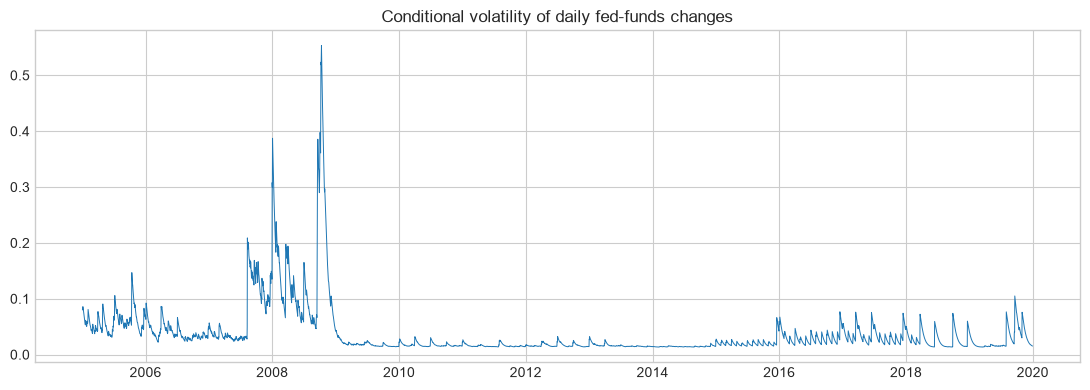

In [8]:
res = best
print("Selected:", table.attrs.get("best"), "BIC=%.2f" % res.bic)
fig = res.plot_diagnostics()
plt.show()
vol = pd.Series(
    np.asarray(res.conditional_volatility, float),
    index=y.index[-len(np.asarray(res.conditional_volatility)):],
)
fig, ax = plt.subplots()
ax.plot(vol, lw=0.7)
ax.set_title("Conditional volatility of daily fed-funds changes")
fig.tight_layout()
plt.show()

## 8. Takeaways

1. **Rate changes** combine serial correlation **and** clustering → natural ARMA–GARCH case.
2. Manual steps show why mean lags enter; **`select_order`** then ranks AR/MA under the same GARCH(1,1) likelihood.
3. Keep **(1,1)** variance until residual energy demands more; prefer BIC on large T.
4. makystats = **joint** mean–variance MLE + manipulable grid search — not ARMA in one package and GARCH in another.

Source: FRED `DFF` (effective federal funds rate).
